# MetaOpticsAI — Complete Design-to-Fabrication Workflow

This notebook walks through every stage of the unified `metaopticsai` pipeline — from material selection and RCWA simulation through PSF/MTF analysis, wavefront decomposition, field propagation, optimization, and GDSII layout export.  An optional final section runs the Groq-backed LLM agent.

**No `pip install` needed** — the repo root is added to `sys.path` automatically.

| Stage | Tool | Output |
|-------|------|--------|
| 0 | *setup* | registry + store |
| 1 | `get_workflow_guide` | design procedure |
| 2 | `list_materials` / `get_material_index` | n(λ) curves |
| 3 | `list_templates` / `get_template` | verified starting point |
| 4 | `validate_design` | constraint check |
| 5 | `run_rcwa_sweep` | phase & transmission library |
| 6 | `get_optimization_tips` | tuning suggestions |
| 7 | `generate_phase_mask` | FZL / axicon / SPP arrays |
| 8 | `analyze_psf` | Strehl ratio, FWHM |
| 9 | `analyze_mtf` | MTF vs. diffraction limit |
| 10 | `zernike_decompose` | wavefront aberrations |
| 11 | `propagate_field` | focal-plane intensity (MetaBox) |
| 12 | `optimize_metalens` | heuristic + gradient |
| 13 | `export_gds` | fabrication-ready GDSII |
| 14 | `run_agent` *(optional)* | LLM-orchestrated run |

## 0. Environment Setup

Add `src/` to `sys.path`, build the single unified **ToolRegistry** and **InMemoryArtifactStore**, and define a one-liner `call()` helper.

In [1]:
from __future__ import annotations
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

# ── path bootstrap (works whether run from examples/ or repo root) ──────────
NOTEBOOK_DIR = Path().resolve()
REPO = NOTEBOOK_DIR.parent if NOTEBOOK_DIR.name == "examples" else NOTEBOOK_DIR
for p in (REPO, REPO / "src"):
    s = str(p)
    if s not in sys.path:
        sys.path.insert(0, s)

# ── build the single unified registry + in-memory store ─────────────────────
from metaopticsai.orchestration.agent import build_registry_and_store

registry, store = build_registry_and_store()

def call(name, args=None):
    """Call any registered tool by name with a plain dict of arguments."""
    return registry.get(name).call_sync(args or {})

from metaopticsai.physics.backends import default_registry as _dr
backends_available = _dr().available()

print(f"Python: {sys.version.split()[0]}")
print(f"Backends available: {backends_available}")
print(f"\nRegistry — {len(registry.names())} tools:")
for n in sorted(registry.names()):
    print(f"  {n}")

Python: 3.11.9
Backends available: ['metabox']

Registry — 20 tools:
  analyze_mtf
  analyze_psf
  compute_center_intensity
  compute_max_intensity
  compute_mtf_volume
  export_gds
  generate_phase_mask
  get_fdtd_library
  get_material_index
  get_optimization_tips
  get_template
  get_workflow_guide
  list_artifacts
  list_materials
  list_templates
  optimize_metalens
  propagate_field
  run_rcwa_sweep
  validate_design
  zernike_decompose


## 1. Canonical Workflow Guide

The `get_workflow_guide` tool returns the seven-step design procedure that the LLM agent also follows.

In [2]:
guide = call("get_workflow_guide")
print(guide["guide"])

# Meta-optics design workflow (verified)

Follow these stages in order. Each stage has one dedicated tool.

## 1. Pick a starting template
Call `list_templates` to see verified recipes, then `get_template(name)` to
retrieve full parameters. Templates are pre-validated: their wavelength,
material, pillar height, and periodicity have been tested to give full
2*pi phase coverage on a diameter sweep.

## 2. Adapt parameters
Modify the template dict to match the user's request:
  - wavelength_nm     : design wavelength in nm  (200 < lambda < 20000)
  - focal_length_mm   : desired focal length in mm
  - diameter_mm       : aperture diameter in mm
  - pillar_material   : one of TiO2, Si, GaN, SiN
  - pillar_height_nm  : 50 < h < 3000
  - min/max_diameter_nm : bracket of pillar diameters to sweep
  - periodicity_nm    : unit-cell pitch (must be > max_diameter + 20 nm)

## 3. Validate
Always call `validate_design` before running physics. It re-checks the
Pydantic constraints (min<max, pillar fi

## 2. Materials Library

MetaBox bundles refractive-index CSV tables for every common metasurface material. `list_materials` returns the names; `get_material_index` does cubic interpolation at any wavelength.

In [3]:
mats = call("list_materials")
print(f"{mats['count']} bundled materials:")
print("  " + ", ".join(mats["materials"]))

# Spot-check: TiO2 at the design wavelength
tio2 = call("get_material_index", {"name": "TiO2", "wavelength_nm": 532.0})
print(f"\nTiO2 @ 532 nm:  n = {tio2['n']:.4f},  k = {tio2['k']:.4e}")
print(f"Valid range:    {tio2['valid_range_um'][0]:.2f} – {tio2['valid_range_um'][1]:.2f} µm")

12 bundled materials:
  GaN, MoO3, N-BK7, Nb2O5, Si3N4, Si_ir, Si_visible, TiO2, ZnO, ZrO2, quartz, sample

TiO2 @ 532 nm:  n = 2.6679,  k = 0.0000e+00
Valid range:    0.43 – 1.53 µm


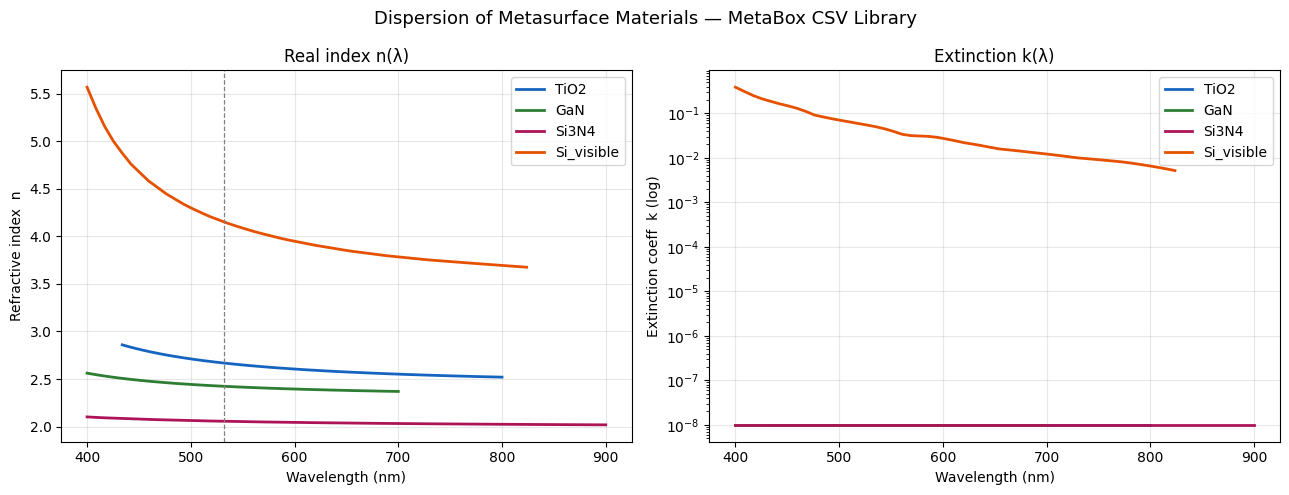

In [4]:
# Refractive index dispersion for common metasurface materials
materials_to_plot = [
    ("TiO2",       "#1565C0", 400, 800),
    ("GaN",        "#2E7D32", 400, 700),
    ("Si3N4",      "#AD1457", 400, 900),
    ("Si_visible", "#E65100", 400, 900),
]

fig, (ax_n, ax_k) = plt.subplots(1, 2, figsize=(13, 5))

for mat, color, wl_min, wl_max in materials_to_plot:
    wls, ns, ks = [], [], []
    for wl in np.linspace(wl_min, wl_max, 60):
        try:
            r = call("get_material_index", {"name": mat, "wavelength_nm": float(wl)})
            wls.append(wl); ns.append(r["n"]); ks.append(r["k"])
        except Exception:
            pass
    if wls:
        ax_n.plot(wls, ns, "-", color=color, lw=2.0, label=mat)
        ax_k.semilogy(wls, [max(k, 1e-8) for k in ks], "-", color=color, lw=2.0, label=mat)

for ax, ylabel, title in [
    (ax_n, "Refractive index  n",     "Real index n(λ)"),
    (ax_k, "Extinction coeff  k (log)", "Extinction k(λ)"),
]:
    ax.set_xlabel("Wavelength (nm)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)

ax_n.axvline(532, color="gray", ls="--", lw=0.9, label="532 nm")
fig.suptitle("Dispersion of Metasurface Materials — MetaBox CSV Library", fontsize=13)
plt.tight_layout()
plt.show()

## 3. Design Templates & Validation

`list_templates` lists pre-verified starting points. `get_template` retrieves the full parameter dict. `validate_design` enforces all geometric and physical constraints via Pydantic.

In [5]:
tpls = call("list_templates")
print(f"{tpls['count']} verified templates:\n")
for t in tpls["templates"]:
    desc = t.get("description", "")
    print(f"  {t['name']:<36} {t['material']:<6} @ {t['wavelength_nm']:.0f} nm")
    if desc:
        print(f"  {'':36} {desc}")
    print()

3 verified templates:

  tio2_metalens_532nm                  TiO2   @ 532 nm

  si_nir_metalens_850nm                Si     @ 850 nm

  gan_uv_metalens_405nm                GaN    @ 405 nm



In [6]:
# Retrieve and validate the standard TiO2 green template
tpl = call("get_template", {"name": "tio2_metalens_532nm"})
params = tpl["template"]["params"]

print("Template parameters:")
for k, v in params.items():
    print(f"  {k:<32} {v}")

val = call("validate_design", {"params": params})
print(f"\n{'Valid:':<24} {val['valid']}")
print(f"{'Numerical aperture:':<24} {val['derived']['numerical_aperture']:.4f}")
print(f"{'f-number:':<24} {val['derived']['f_number']:.2f}")
print(f"{'Aspect ratio:':<24} {val['derived']['aspect_ratio']:.2f}")
if val.get("warnings"):
    for w in val["warnings"]:
        print(f"  ⚠  {w}")

Template parameters:
  wavelength_nm                    532.0
  focal_length_mm                  2.0
  diameter_mm                      0.5
  pillar_material                  TiO2
  pillar_height_nm                 600.0
  min_diameter_nm                  80.0
  max_diameter_nm                  300.0
  periodicity_nm                   350.0

Valid:                   True
Numerical aperture:      0.1240
f-number:                4.00
Aspect ratio:            3.16


In [7]:
# Validation catches constraint violations
bad = call("validate_design", {
    "params": {
        "wavelength_nm":   532.0,
        "min_diameter_nm": 320.0,
        "max_diameter_nm": 100.0,  # min > max — invalid
        "periodicity_nm":  50.0,   # period < diameter — invalid
    }
})
print(f"Valid: {bad['valid']}")
for err in bad.get("errors", []):
    print(f"  ✗  {err}")

Valid: False
  ✗  {'field': 'periodicity_nm', 'msg': 'Input should be greater than 100'}


## 4. FDTD Reference Library

`get_fdtd_library` exposes pre-computed phase-vs-dimension curves from published FDTD simulations — useful for a quick sanity check before running RCWA.

In [8]:
fdtd = call("get_fdtd_library")
print(f"FDTD library — {fdtd['count']} entries:\n")
for e in fdtd["entries"]:
    print(f"  {e['wavelength_nm']:.0f} nm  {e['material']:<6}  {e['shape']:<10}"
          f"  h={e['height_nm']:.0f} nm  p={e['period_nm']:.0f} nm  "
          f"  {e['n_samples']} samples  ({e['reference'][:50]}...)"
          if len(e.get('reference',''))>50
          else f"  {e['wavelength_nm']:.0f} nm  {e['material']:<6}  {e['shape']:<10}"
               f"  h={e['height_nm']:.0f} nm  p={e['period_nm']:.0f} nm  "
               f"  {e['n_samples']} samples  ({e.get('reference','')})"
         )

FDTD library — 5 entries:

  405 nm  TiO2    Fin         h=600 nm  p=200 nm    7 samples  (Ahmed et al., Opt. Mat. Express 10.2 (2020))
  532 nm  TiO2    Fin         h=600 nm  p=325 nm    7 samples  (Ahmed et al., Opt. Mat. Express 10.2 (2020))
  633 nm  Silicon  Cylinder    h=280 nm  p=250 nm    8 samples  (Standard Si nanodisk at 633nm)
  850 nm  Silicon  Cylinder    h=475 nm  p=390 nm    12 samples  (Si cylinder at 850nm)
  1064 nm  Silicon  Cylinder    h=170 nm  p=620 nm    9 samples  (Si cylinder at 1064nm)


## 5. RCWA Unit-Cell Sweep

`run_rcwa_sweep` runs a diameter sweep through the **MetaBox RCWA engine** (TensorFlow). Each pillar diameter in the sweep gives one complex transmission value; the phase and amplitude are plotted below.

In [9]:
sweep_r = call("run_rcwa_sweep", {
    "wavelength_nm":   532.0,
    "pillar_material": "TiO2",
    "pillar_height_nm": 600.0,
    "period_nm":        350.0,
    "min_diameter_nm":  80.0,
    "max_diameter_nm":  300.0,
    "n_samples":        25,
    "backend":          "auto",
})
sweep_handle = sweep_r["handle"]

print(f"Backend:           {sweep_r['backend']}")
print(f"Phase coverage:    {sweep_r['phase_coverage_2pi_fraction']:.1%}  "
      f"({'✓ ≥ 90 %' if sweep_r['phase_coverage_2pi_fraction'] >= 0.9 else '✗ < 90 %'})")
print(f"Mean transmission: {sweep_r['mean_transmission']:.1%}  "
      f"({'✓ ≥ 70 %' if sweep_r['mean_transmission'] >= 0.7 else '✗ < 70 %'})")
print(f"Elapsed:           {sweep_r['elapsed_s']:.2f} s")
print(f"Advice:            {sweep_r['advice']}")

100%|██████████| 2/2 [00:01<00:00,  1.01it/s]

Backend:           metabox
Phase coverage:    114.2%  (✓ ≥ 90 %)
Mean transmission: 74.1%  (✓ ≥ 70 %)
Elapsed:           2.01 s
Advice:            Phase coverage looks good for metalens design.


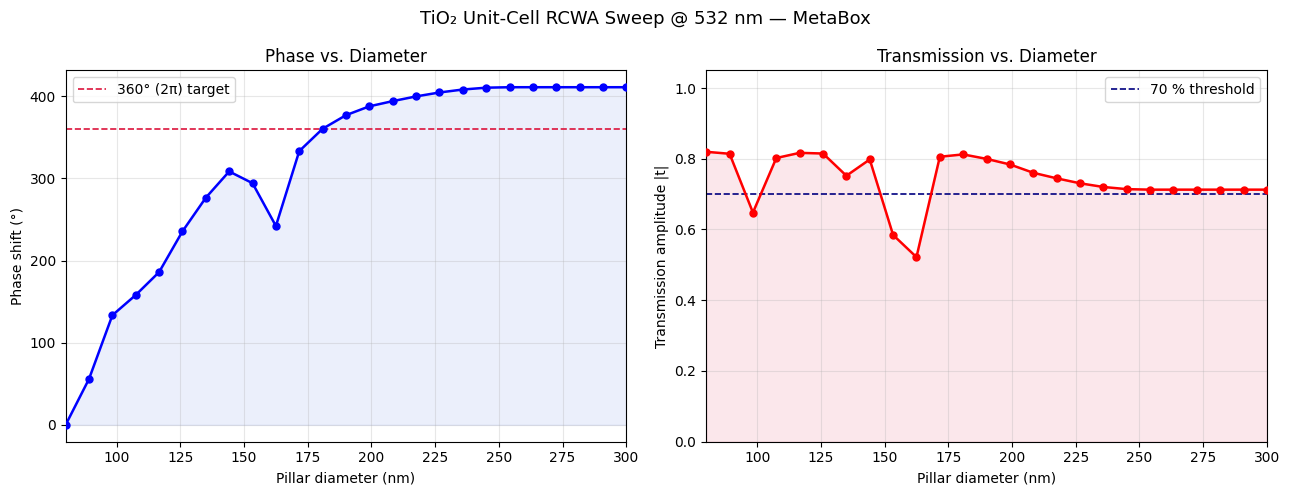

In [10]:
sweep = store.get(sweep_handle).payload
d_nm  = np.array(sweep["diameters_nm"])
amp   = np.array(sweep["amplitudes"])
phi   = np.degrees(np.array(sweep["phases_rad"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.plot(d_nm, phi, "b-o", ms=5, lw=1.8, zorder=3)
ax1.fill_between(d_nm, phi, 0, alpha=0.10, color="royalblue")
ax1.axhline(360, color="crimson", ls="--", lw=1.2, label="360° (2π) target")
ax1.set_xlabel("Pillar diameter (nm)")
ax1.set_ylabel("Phase shift (°)")
ax1.set_title("Phase vs. Diameter")
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_xlim(d_nm[0], d_nm[-1])

ax2.plot(d_nm, amp, "r-o", ms=5, lw=1.8, zorder=3)
ax2.fill_between(d_nm, amp, 0, alpha=0.10, color="crimson")
ax2.axhline(0.7, color="navy", ls="--", lw=1.2, label="70 % threshold")
ax2.set_xlabel("Pillar diameter (nm)")
ax2.set_ylabel("Transmission amplitude |t|")
ax2.set_title("Transmission vs. Diameter")
ax2.set_ylim(0, 1.05)
ax2.legend()
ax2.grid(alpha=0.3)
ax2.set_xlim(d_nm[0], d_nm[-1])

fig.suptitle(f"TiO₂ Unit-Cell RCWA Sweep @ {sweep['wavelength_nm']:.0f} nm — MetaBox", fontsize=13)
plt.tight_layout()
plt.show()

## 6. Optimization Tips

`get_optimization_tips` reads the sweep metrics and returns human-readable suggestions.

In [11]:
tips_r = call("get_optimization_tips", {"result": {
    "phase_coverage_2pi_fraction": sweep_r["phase_coverage_2pi_fraction"],
    "mean_transmission":          sweep_r["mean_transmission"],
}})
print("Optimization tips:")
for tip in tips_r["tips"]:
    print(f"  • {tip}")

Optimization tips:
  • Metrics are borderline. Try increasing n_samples to 30-40 for a smoother phase curve, then re-simulate.


## 7. Phase Mask Generation

`generate_phase_mask` supports three canonical element types:

| `mask_type` | Description |
|-------------|-------------|
| `fzl`       | Fresnel zone lens — focusing |
| `axicon`    | Conical phase — Bessel beam |
| `spp`       | Spiral phase plate — optical vortex |

All masks are stored by handle and retrieved from the `store` for plotting.

In [12]:
# Design constants used throughout the rest of the notebook
WAVELENGTH = 532.0   # nm
DIAMETER   = 200.0   # µm  aperture
PIXEL      = 0.35    # µm  (matches RCWA period = 350 nm)
FOCAL      = 400.0   # µm  focal length for FZL

# --- Fresnel zone lens (focusing) -------------------------------------------
fzl_r = call("generate_phase_mask", {
    "mask_type":      "fzl",
    "wavelength_nm":  WAVELENGTH,
    "diameter_um":    DIAMETER,
    "pixel_size_um":  PIXEL,
    "focal_length_um": FOCAL,
})
fzl_handle = fzl_r["handle"]

# --- Axicon (Bessel beam) ----------------------------------------------------
axicon_r = call("generate_phase_mask", {
    "mask_type":      "axicon",
    "wavelength_nm":  WAVELENGTH,
    "diameter_um":    DIAMETER,
    "pixel_size_um":  PIXEL,
    "cone_angle_deg": 1.5,
})

# --- Spiral phase plate (ℓ = 2) ----------------------------------------------
spp_r = call("generate_phase_mask", {
    "mask_type":    "spp",
    "wavelength_nm": WAVELENGTH,
    "diameter_um":  DIAMETER,
    "pixel_size_um": PIXEL,
    "spp_charge":   2,
})

N_pixels = fzl_r["shape"][0]
print(f"Pixel array size: {N_pixels} × {N_pixels}  ({DIAMETER:.0f} µm / {PIXEL} µm/px)")
for label, r in [("FZL   ", fzl_r), ("Axicon", axicon_r), ("SPP   ", spp_r)]:
    print(f"  {label}  phase ∈ [{r['phase_min_rad']:+.3f}, {r['phase_max_rad']:+.3f}] rad  "
          f"  shape {r['shape']}")

Pixel array size: 570 × 570  (200 µm / 0.35 µm/px)
  FZL     phase ∈ [+0.000, +6.283] rad    shape [570, 570]
  Axicon  phase ∈ [+0.000, +6.282] rad    shape [570, 570]
  SPP     phase ∈ [+0.000, +6.280] rad    shape [570, 570]


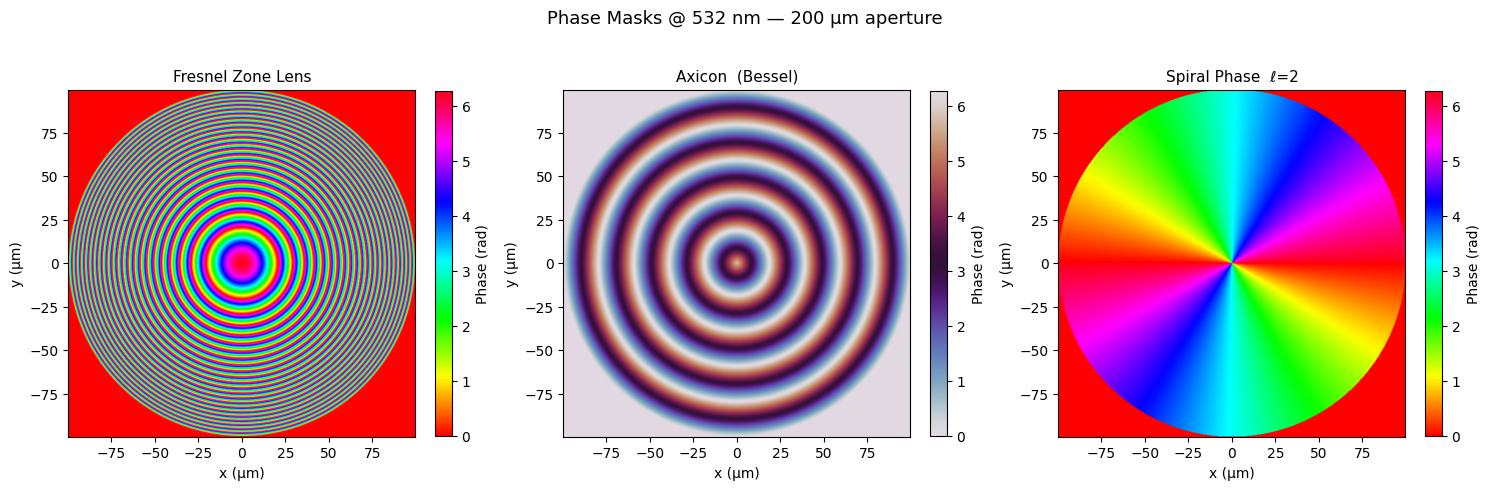

In [13]:
mask_info = [
    (fzl_r["handle"],    "Fresnel Zone Lens",  "hsv"),
    (axicon_r["handle"],  "Axicon  (Bessel)",   "twilight"),
    (spp_r["handle"],     "Spiral Phase  ℓ=2", "hsv"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, (handle, label, cmap) in zip(axes, mask_info):
    mask = store.get(handle).payload
    N    = mask.shape[0]
    ext  = N * PIXEL / 2
    im   = ax.imshow(mask, extent=[-ext, ext, -ext, ext],
                     cmap=cmap, origin="lower")
    ax.set_title(label, fontsize=11)
    ax.set_xlabel("x (µm)")
    ax.set_ylabel("y (µm)")
    plt.colorbar(im, ax=ax, label="Phase (rad)", fraction=0.045)

fig.suptitle(f"Phase Masks @ {WAVELENGTH:.0f} nm — {DIAMETER:.0f} µm aperture", fontsize=13)
plt.tight_layout()
plt.show()

## 8. PSF Analysis

`analyze_psf` applies the Fraunhofer FFT to the phase mask and returns the point-spread function, Strehl ratio, and FWHM. The PSF result is stored by handle for downstream MTF computation.

In [14]:
psf_r = call("analyze_psf", {
    "mask_handle":    fzl_handle,
    "wavelength_nm":  WAVELENGTH,
    "pixel_size_um":  PIXEL,
    "focal_length_um": FOCAL,
    "pad_factor":     4,
})
psf_handle = psf_r["handle"]

NA = (DIAMETER / 2) / np.sqrt((DIAMETER / 2)**2 + FOCAL**2)
diff_limit_um = 0.61 * (WAVELENGTH * 1e-3) / NA

print(f"Strehl ratio:           {psf_r['strehl_ratio']:.4f}  (1.0 = diffraction limited)")
print(f"FWHM (x):               {psf_r['fwhm_x_um']:.3f} µm")
print(f"Airy disk radius (est): {diff_limit_um:.3f} µm  (0.61 λ/NA,  NA={NA:.3f})")
print(f"PSF array shape:        {psf_r['shape']}")

Strehl ratio:           0.0001  (1.0 = diffraction limited)
FWHM (x):               2.668 µm
Airy disk radius (est): 1.338 µm  (0.61 λ/NA,  NA=0.243)
PSF array shape:        [2280, 2280]


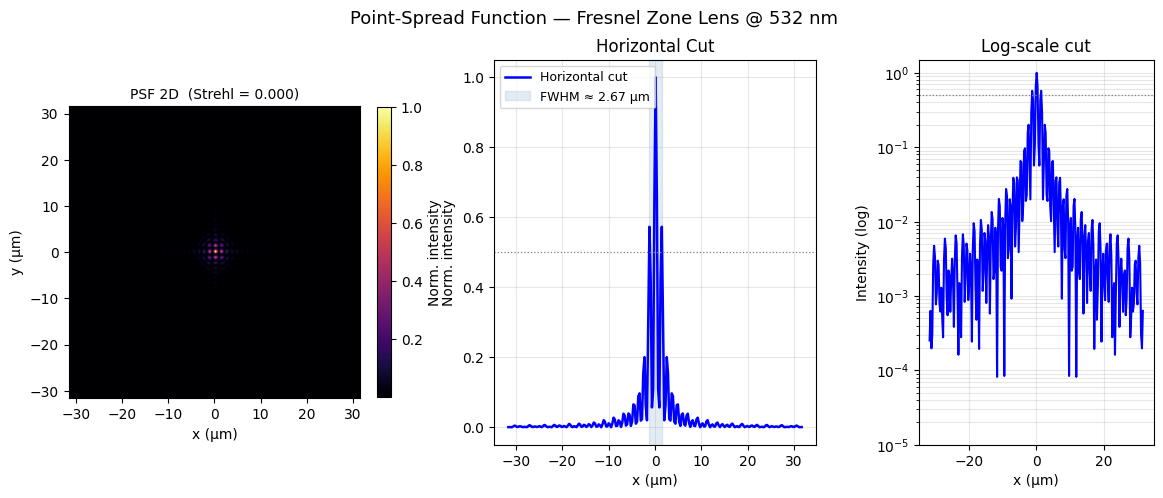

In [15]:
psf_art  = store.get(psf_handle).payload
psf      = psf_art["psf_2d"]
x_um     = np.array(psf_art["x_um"])

N       = psf.shape[0]
half    = N // 2
fwhm    = psf_r["fwhm_x_um"]
px_size = abs(x_um[1] - x_um[0]) if len(x_um) > 1 else PIXEL
win     = max(int(12 * fwhm / px_size), 60)
crop    = min(win, half - 1)

slc  = slice(half - crop, half + crop)
psf_c = psf[slc, slc]
x_c   = x_um[slc]

fig = plt.figure(figsize=(14, 5))
gs  = fig.add_gridspec(1, 3, width_ratios=[1.1, 1.1, 0.8], wspace=0.35)

# 2-D PSF
ax0 = fig.add_subplot(gs[0])
im  = ax0.imshow(psf_c,
                 extent=[x_c[0], x_c[-1], x_c[0], x_c[-1]],
                 cmap="inferno", origin="lower")
ax0.set_title(f"PSF 2D  (Strehl = {psf_r['strehl_ratio']:.3f})", fontsize=10)
ax0.set_xlabel("x (µm)")
ax0.set_ylabel("y (µm)")
plt.colorbar(im, ax=ax0, label="Norm. intensity", fraction=0.045)

# 1-D horizontal cut
ax1 = fig.add_subplot(gs[1])
row = psf[half, slc]
row_n = row / row.max()
ax1.plot(x_c, row_n, "b-", lw=1.8, label="Horizontal cut")
above = x_c[row_n >= 0.5]
if len(above) >= 2:
    ax1.axvspan(above[0], above[-1], alpha=0.15, color="steelblue",
                label=f"FWHM ≈ {fwhm:.2f} µm")
ax1.axhline(0.5, color="gray", ls=":", lw=0.9)
ax1.set_xlabel("x (µm)")
ax1.set_ylabel("Norm. intensity")
ax1.set_title("Horizontal Cut")
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3)

# log-scale cut to see sidelobes
ax2 = fig.add_subplot(gs[2])
ax2.semilogy(x_c, np.maximum(row_n, 1e-5), "b-", lw=1.5)
ax2.axhline(0.5, color="gray", ls=":", lw=0.9, label="FWHM")
ax2.set_xlabel("x (µm)")
ax2.set_ylabel("Intensity (log)")
ax2.set_title("Log-scale cut")
ax2.grid(alpha=0.3, which="both")
ax2.set_ylim(1e-5, 1.5)

fig.suptitle("Point-Spread Function — Fresnel Zone Lens @ 532 nm", fontsize=13)
plt.show()

## 9. MTF Analysis

`analyze_mtf` computes the radially-averaged Modulation Transfer Function from the stored PSF and overlays the theoretical diffraction-limited OTF.

In [16]:
mtf_r = call("analyze_mtf", {
    "psf_handle":     psf_handle,
    "wavelength_nm":  WAVELENGTH,
    "pixel_size_um":  PIXEL,
    "focal_length_um": FOCAL,
})
mtf_handle = mtf_r["handle"]
print(f"MTF50:          {mtf_r['mtf50_lpmm']:.1f} lp/mm")
print(f"Cutoff (th.):   {mtf_r['cutoff_lpmm']:.1f} lp/mm")

MTF50:          2.8 lp/mm
Cutoff (th.):   1426.1 lp/mm


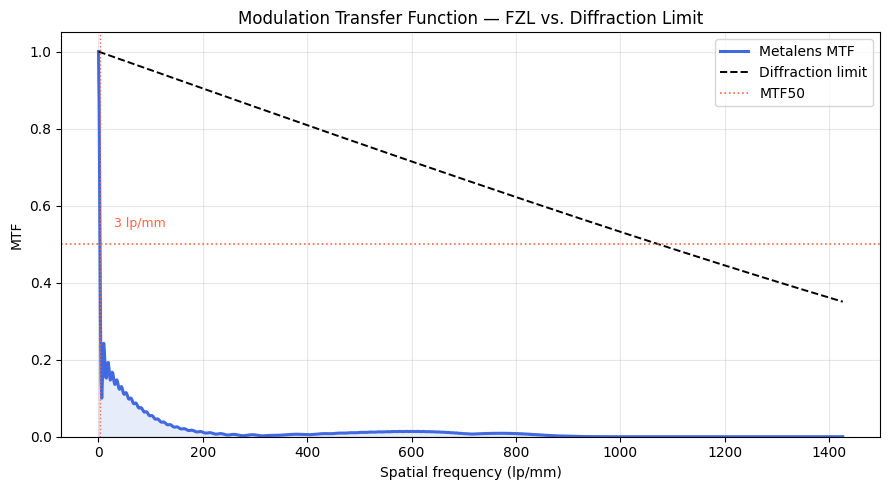

In [17]:
mtf_art = store.get(mtf_handle).payload
freqs   = np.array(mtf_art["freqs_lpmm"])
mtf_rad = np.array(mtf_art["mtf_radial"])
mtf_dl  = np.array(mtf_art["mtf_diffraction_limit"])

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(freqs, mtf_rad, color="royalblue", lw=2.2, label="Metalens MTF")
ax.fill_between(freqs, mtf_rad, 0, alpha=0.12, color="royalblue")
ax.plot(freqs, mtf_dl, "k--", lw=1.4, label="Diffraction limit")
ax.axhline(0.5, color="tomato", ls=":", lw=1.2, label="MTF50")
if mtf_r["mtf50_lpmm"] > 0:
    ax.axvline(mtf_r["mtf50_lpmm"], color="tomato", ls=":", lw=1.0)
    ax.annotate(f"{mtf_r['mtf50_lpmm']:.0f} lp/mm",
                xy=(mtf_r["mtf50_lpmm"], 0.5), xytext=(10, 12),
                textcoords="offset points", color="tomato", fontsize=9)
ax.set_xlabel("Spatial frequency (lp/mm)")
ax.set_ylabel("MTF")
ax.set_title("Modulation Transfer Function — FZL vs. Diffraction Limit")
ax.set_ylim(0, 1.05)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Zernike Wavefront Decomposition

`zernike_decompose` projects the phase mask onto the first 15 Noll-indexed Zernike polynomials and returns the dominant aberration terms.

In [18]:
zernike_r = call("zernike_decompose", {
    "mask_handle": fzl_handle,
    "n_terms":     15,
})
zernike_handle = zernike_r["handle"]
print(f"Analyzed {zernike_r['n_terms_analyzed']} Zernike terms\n")
print(f"{'Z#':<5} {'Name':<32} {'Coeff (rad)':>12}")
print("-" * 52)
for ab in zernike_r["top_aberrations"]:
    bar = "█" * max(1, int(abs(ab["coeff_rad"]) * 3))
    sign = "+" if ab["coeff_rad"] >= 0 else "-"
    print(f"Z{ab['noll']:<4} {ab['name']:<32} {sign}{abs(ab['coeff_rad']):.4f}   {bar}")

Analyzed 15 Zernike terms

Z#    Name                              Coeff (rad)
----------------------------------------------------
Z1    Piston                           +3.1458   █████████
Z4    Defocus                          -0.0673   █
Z15   Secondary Coma (h)               -0.0154   █
Z14   Secondary Coma (v)               -0.0154   █
Z8    Coma (horizontal)                -0.0125   █


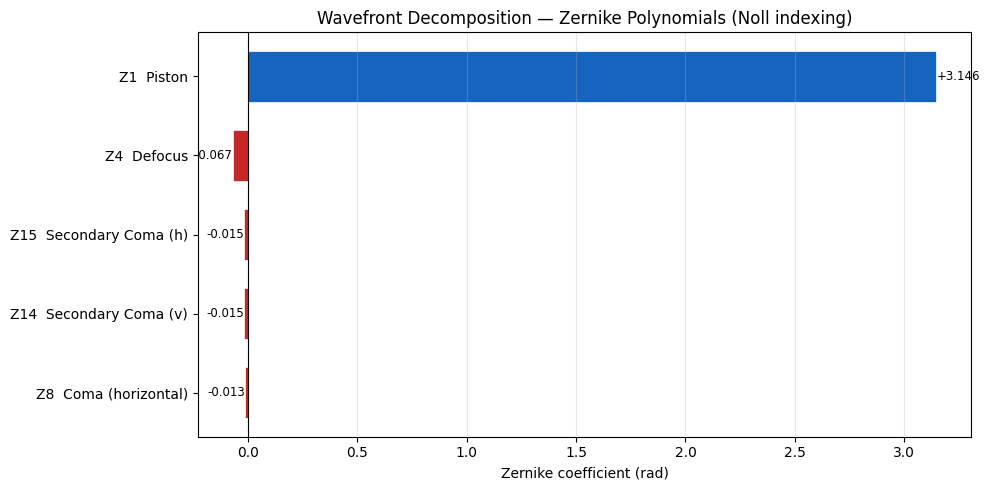

In [19]:
top    = zernike_r["top_aberrations"]
labels = [f"Z{a['noll']}  {a['name']}" for a in top]
values = [a["coeff_rad"] for a in top]
colors = ["#1565C0" if v >= 0 else "#C62828" for v in values]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(labels[::-1], values[::-1], color=colors[::-1],
               edgecolor="white", linewidth=0.5, height=0.65)
ax.axvline(0, color="black", lw=0.8)
for bar, val in zip(bars, values[::-1]):
    xpos = val + (0.002 if val >= 0 else -0.002)
    ha = "left" if val >= 0 else "right"
    ax.text(xpos, bar.get_y() + bar.get_height() / 2,
            f"{val:+.3f}", va="center", ha=ha, fontsize=8.5)
ax.set_xlabel("Zernike coefficient (rad)")
ax.set_title("Wavefront Decomposition — Zernike Polynomials (Noll indexing)")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Angular-Spectrum Field Propagation

`propagate_field` calls the **MetaBox backend** to propagate the optical field from the metasurface plane to a target distance using the angular-spectrum method.

In [20]:
prop_r = call("propagate_field", {
    "mask_handle":             fzl_handle,
    "wavelength_nm":           WAVELENGTH,
    "pixel_size_um":           PIXEL,
    "propagation_distance_um": FOCAL,
    "refractive_index":        1.0,
})
prop_handle = prop_r["handle"]
print(f"Propagation distance: {FOCAL:.0f} µm  (focal plane)")
print(f"Output field shape:   {prop_r['shape']}")
print(f"Peak intensity:       {prop_r['peak_intensity']:.4f}")
print(f"Backend:              {prop_r['backend']}")

Propagation distance: 400 µm  (focal plane)
Output field shape:   [570, 570]
Peak intensity:       14758.6816
Backend:              metabox


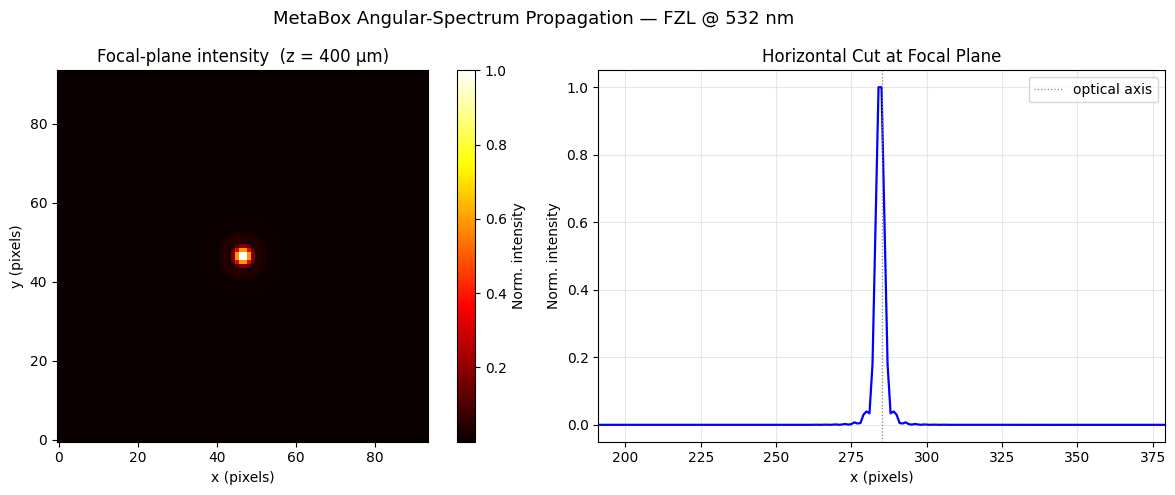

In [21]:
prop_art  = store.get(prop_handle).payload
intensity = prop_art["psf_2d"]
N         = intensity.shape[0]
half      = N // 2
crop      = max(N // 12, 20)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

im = axes[0].imshow(
    intensity[half - crop : half + crop, half - crop : half + crop],
    cmap="hot", origin="lower",
)
axes[0].set_title(f"Focal-plane intensity  (z = {FOCAL:.0f} µm)")
axes[0].set_xlabel("x (pixels)")
axes[0].set_ylabel("y (pixels)")
plt.colorbar(im, ax=axes[0], label="Norm. intensity", fraction=0.045)

mid = intensity[half, :]
norm_mid = mid / max(mid.max(), 1e-9)
xpx = np.arange(len(mid))
axes[1].plot(xpx, norm_mid, "b-", lw=1.6)
axes[1].axvline(half, color="gray", ls=":", lw=0.9, label="optical axis")
axes[1].set_xlabel("x (pixels)")
axes[1].set_ylabel("Norm. intensity")
axes[1].set_title("Horizontal Cut at Focal Plane")
axes[1].set_xlim(half - 2 * crop, half + 2 * crop)
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.suptitle("MetaBox Angular-Spectrum Propagation — FZL @ 532 nm", fontsize=13)
plt.tight_layout()
plt.show()

## 12. Metalens Optimization

`optimize_metalens` takes a stored RCWA sweep and iteratively improves the Strehl ratio estimate.  Two methods are available:

- **`heuristic`** — fast, sweep-based estimator (no TF required)
- **`gradient`** — TF gradient tape through the MetaBox assembly module

In [22]:
# ── Heuristic optimizer (always available) ──────────────────────────────────
opt_r = call("optimize_metalens", {
    "sweep_handle":  sweep_handle,
    "method":        "heuristic",
    "target_strehl": 0.85,
    "max_iters":     30,
})
design_handle = opt_r["handle"]

print("Heuristic optimization:")
print(f"  Method:          {opt_r['method']}")
print(f"  Achieved Strehl: {opt_r['achieved_strehl']:.4f}")
print(f"  Target Strehl:   0.85  →  {'MET ✓' if opt_r['target_met'] else 'not reached'}")
print(f"  Iterations:      {opt_r['iterations_run']}")
print(f"  Design handle:   {design_handle}")

Heuristic optimization:
  Method:          heuristic
  Achieved Strehl: 0.5488
  Target Strehl:   0.85  →  not reached
  Iterations:      30
  Design handle:   159f2f5ec466


In [23]:
# ── Gradient optimizer (requires TensorFlow / MetaBox) ──────────────────────
from metaopticsai.physics.backends.metabox import MetaboxBackend

if MetaboxBackend().is_available():
    grad_r = call("optimize_metalens", {
        "sweep_handle":  sweep_handle,
        "method":        "gradient",
        "target_strehl": 0.90,
        "max_iters":     20,
        "learning_rate": 2e-9,
    })
    print("Gradient optimization (MetaBox + TF):")
    print(f"  Achieved Strehl: {grad_r['achieved_strehl']:.4f}")
    print(f"  Iterations:      {grad_r['iterations_run']}")
    print(f"  Target met:      {grad_r['target_met']}")
else:
    print("TensorFlow / MetaBox not available — gradient optimization skipped.")
    print("Install with:  pip install metaopticsai[tf]")

 12%|█▎        | 1/8 [00:06<00:42,  6.07s/it]


KeyboardInterrupt: 

## 13. GDSII Layout Export

`export_gds` quantizes the Fresnel phase mask into discrete phase levels, maps each level to a pillar diameter from the RCWA library, and writes a fabrication-ready `.gds` file via `gdsfactory`.

In [24]:
import os

gds_r = call("export_gds", {
    "design_handle": design_handle,
    "sweep_handle":  sweep_handle,
    "output_name":   "tio2_532nm_metalens",
    "period_nm":     350.0,
    "pixel_size_um": PIXEL,
    "n_levels":      8,
    "shape":         "Cylinder",
    "is_circular":   True,
})

print(f"GDS file:    {gds_r['path']}")
print(f"File size:   {gds_r['size_kb']:.1f} kB")
print(f"Elapsed:     {gds_r['elapsed_s']:.2f} s")
print(f"File exists: {os.path.exists(gds_r['path'])}")

GDS file:    D:\metacode\outputs\tio2_532nm_metalens.gds
File size:   489.6 kB
Elapsed:     0.83 s
File exists: True


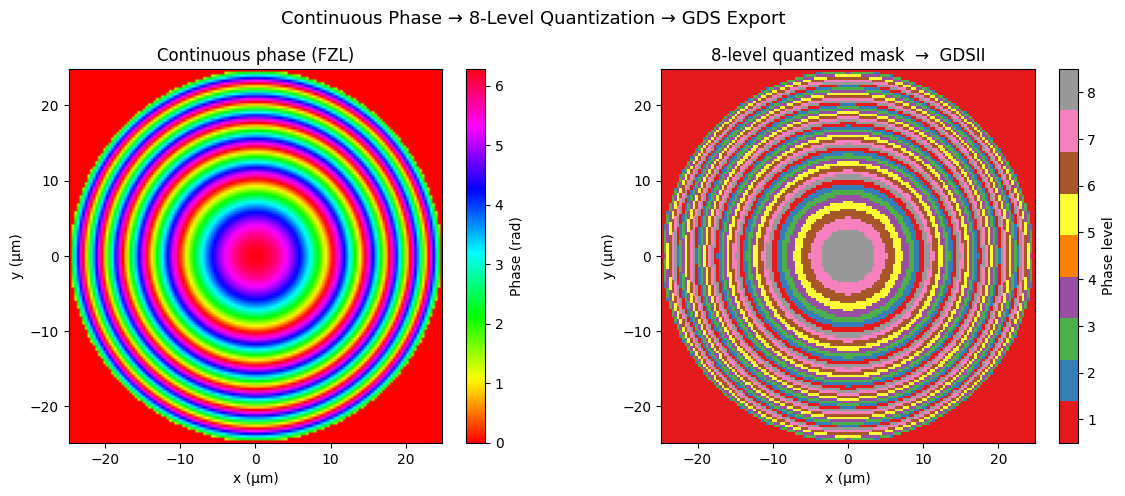

Phase bins (levels 1–8): [0.0, 45.0, 90.0, 135.0, 180.0, 225.0, 270.0, 315.0]


In [25]:
# Visualize the quantized phase mask that was written to the GDS
from metaopticsai.phase import profiles, quantization

mask_gds = profiles.fresnel_zone_lens(
    wavelength_nm=sweep["wavelength_nm"],
    focal_length_um=100.0,
    diameter_um=50.0,
    pixel_size_um=PIXEL,
    circular=True,
)
quant_mask, bins = quantization.quantize(mask_gds, n_levels=8)

N   = quant_mask.shape[0]
ext = N * PIXEL / 2

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

im1 = ax1.imshow(mask_gds, extent=[-ext, ext, -ext, ext],
                 cmap="hsv", origin="lower")
ax1.set_title("Continuous phase (FZL)")
ax1.set_xlabel("x (µm)"); ax1.set_ylabel("y (µm)")
plt.colorbar(im1, ax=ax1, label="Phase (rad)", fraction=0.045)

im2 = ax2.imshow(quant_mask.astype(float), extent=[-ext, ext, -ext, ext],
                 cmap="Set1", origin="lower", interpolation="nearest",
                 vmin=0.5, vmax=8.5)
ax2.set_title("8-level quantized mask  →  GDSII")
ax2.set_xlabel("x (µm)"); ax2.set_ylabel("y (µm)")
cb = plt.colorbar(im2, ax=ax2, label="Phase level", fraction=0.045,
                  ticks=range(1, 9))

fig.suptitle("Continuous Phase → 8-Level Quantization → GDS Export", fontsize=13)
plt.tight_layout()
plt.show()
print(f"Phase bins (levels 1–8): {[round(b, 3) for b in bins]}")

## 14. In-Memory Artifact Store — Inventory

`list_artifacts` lists every handle currently in the store.  Handles are the currency that lets tools pass results between each other without copying arrays.

In [26]:
artifacts = call("list_artifacts")
print(f"Store contains {len(artifacts)} artifacts:\n")
print(f"{'Handle':<44} {'Kind':<18} {'Metadata key sample'}")
print("-" * 90)
for a in artifacts:
    meta_sample = ", ".join(f"{k}={v}" for k, v in list(a.get("metadata", {}).items())[:2])
    print(f"{a['handle']:<44} {a['kind']:<18} {meta_sample}")

Store contains 10 artifacts:

Handle                                       Kind               Metadata key sample
------------------------------------------------------------------------------------------
d625918a2378                                 rcwa_sweep         wavelength_nm=532.0, material=TiO2
d1d24477ed83                                 phase_mask         mask_type=fzl, wavelength_nm=532.0
656d6d2d15e4                                 phase_mask         mask_type=axicon, wavelength_nm=532.0
264bfdebb5f2                                 phase_mask         mask_type=spp, wavelength_nm=532.0
05eb54bd93b3                                 psf                wavelength_nm=532.0
bd07fba01b68                                 mtf                
2e6024b0f180                                 zernike            
309d39b6b1b3                                 psf                wavelength_nm=532.0, propagation_distance_um=400.0
159f2f5ec466                                 metalens_design    ach

## 15. LLM Agent — Groq-Orchestrated Run  *(optional)*

`run_agent` passes a free-text design request to the Groq LLM, which autonomously calls the tools above in the correct order.  Requires `GROQ_API_KEY` (free at https://console.groq.com/keys).

Set it with:
```bash
export GROQ_API_KEY=gsk_...
# or add GROQ_API_KEY=... to config/.env
```

In [27]:
import os, json
from metaopticsai.orchestration.groq_client import load_env

load_env()

if not os.environ.get("GROQ_API_KEY"):
    print("GROQ_API_KEY not set — skipping live agent run.")
    print("Set it in config/.env or export it in your shell, then re-run this cell.")
else:
    from metaopticsai.orchestration.agent import run_agent
    from metaopticsai.orchestration.agent import build_registry_and_store as _brs

    agent_registry, agent_store = _brs()   # fresh store for the agent run

    result = run_agent(
        "Design a TiO2 metalens for green light (532 nm). "
        "Start from the verified template, validate it, run a 20-point RCWA sweep, "
        "and report phase coverage and mean transmission.",
        registry=agent_registry,
        store=agent_store,
    )

    print("=== Agent tool calls ===")
    for i, tc in enumerate(result.tool_calls, 1):
        r = tc["result"]
        if isinstance(r, dict) and r.get("ok") is False:
            status = f"ERROR: {r.get('error')}"
        elif tc["name"] == "run_rcwa_sweep":
            status = (f"backend={r.get('backend')}, "
                      f"cov={r.get('phase_coverage_2pi_fraction', 0):.1%}, "
                      f"trans={r.get('mean_transmission', 0):.1%}")
        else:
            status = json.dumps(r, default=str)[:120]
        print(f"  [{i}] {tc['name']:<28} iter={tc['iteration']}")
        print(f"       {status}")

    print("\n=== Agent response ===")
    print(result.final_text)
    print(f"\n(iterations={result.iterations}, stopped_on={result.stopped_on}, "
          f"tool_calls={len(result.tool_calls)})")

GROQ_API_KEY not set — skipping live agent run.
Set it in config/.env or export it in your shell, then re-run this cell.
